# CONCLUSION — NextWatch

Synthèse transversale des notebooks :

| Notebook | Rôle |
| --- | --- |
| `EDA_NextWatch.ipynb` | Exploration, biais, genres |
| `MODEL_BASELINE.ipynb` | Dummy + heuristique overlap/mean |
| `MODEL_CF.ipynb` | UserCF, FilmCF, hybride |
| `MODEL_CLUSTER.ipynb` | Experts sexe / âge / catégories + fusion |

Protocole commun : **mode produit** (âge + sexe + 1–3 films), Precision@5.

**Variance & popularité** (section 3) : charger les exports `results/eval_*.json` produits en relançant les trois notebooks modèles.


## 1. Ce que l'EDA impose

- Catalogue MovieLens 100k, ~94 % de sparsité ; Drama / Comedy dominent.
- Hommes sur-représentés ; le métier (`occupation`) est hors scope.
- « Plus noté » ≠ « plus aimé » : la popularité (volume) ne doit pas être un facteur modèle (charter).
- Signal âge/sexe existant mais **faible** face au collaborative filtering.


## 2. Résultats types (ordre de grandeur, mode produit, `TRAIN_FRAC≈0.25`)

À **reproduire** en relançant chaque notebook (les chiffres exacts dépendent du split et des hypers) :

| Famille | Méthode | P@5 typique | vs baseline |
| --- | --- | --- | --- |
| Référence | Dummy | ~0.02–0.03 | — |
| Référence | Baseline overlap+mean | ~0.19 | plancher |
| CF | Film–Film | ~0.23–0.27 | léger gain |
| CF | User–User | ~0.35–0.36 | fort gain |
| CF | Hybride (α film bas) | ≈ UserCF | surtout porté par UserCF |
| Cluster | Expert sexe | ~0.32 | utile |
| Cluster | Expert âge / catégories | ~0.20–0.24 | faible |
| Cluster | Fusion soft | ~0.28–0.29 | bat baseline, ≤ meilleur expert / UserCF |

Avec **`TRAIN_FRAC=0.7`** (Optuna), les P@5 absolus **baissent** (test plus dur) : comparer les modèles **à split fixé**, pas les scores entre runs à TRAIN_FRAC différents.


## 3. Variance P@5 & popularité (tous modèles)

Prérequis : `results/eval_baseline.json`, `eval_cf.json`, `eval_cluster.json` (relancer `MODEL_*`).

1. **Variance** : P@5 moyen ± écart-type entre cas.
2. **Popularité** : part des top-5 dans le top-20 / top-100 train (volume) — diagnostic seulement, pas une feature (charter).


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

_ROOT = next(
    p for p in [Path("."), Path("..")]
    if (p / "scripts" / "eval_diagnostics.py").exists()
)
sys.path.insert(0, str((_ROOT / "scripts").resolve()))

from eval_diagnostics import (
    find_results_dir,
    flatten_methods,
    load_eval_bundles,
    plot_p5_variance,
    plot_popularity,
    popularity_table,
    shared_film_n_ratings,
    variance_table,
)

RESULTS = find_results_dir()
bundles = load_eval_bundles(RESULTS)
print(f"Bundles trouvés dans {RESULTS} : {len(bundles)}")
for b in bundles:
    print(
        f"  - {b.get('source')}: {len(b.get('methods', {}))} méthodes | "
        f"n_cases={b.get('n_cases')} | seed={b.get('random_state')} | "
        f"TRAIN_FRAC={b.get('train_frac')}"
    )

if not bundles:
    raise FileNotFoundError(
        "Aucun results/eval_*.json — lance d'abord MODEL_BASELINE, MODEL_CF, MODEL_CLUSTER."
    )

seeds = {b.get("random_state") for b in bundles}
fracs = {b.get("train_frac") for b in bundles}
if len(seeds) > 1 or len(fracs) > 1:
    print(
        "\nAttention : seeds ou TRAIN_FRAC différents entre bundles — "
        "la comparaison reste indicative."
    )


Bundles trouvés dans C:\Users\tombo\Documents\cours\data\lab\NextWatch\results : 2
  - cf: 4 méthodes | n_cases=937 | seed=42 | TRAIN_FRAC=0.65
  - cluster: 6 méthodes | n_cases=940 | seed=38 | TRAIN_FRAC=0.65

Attention : seeds ou TRAIN_FRAC différents entre bundles — la comparaison reste indicative.


### 3.1 Variance des P@5


,method,source,P@5,P@10,var_P@5,écart-type,n_cases
0,cluster/cluster_fusion,cluster,0.2030,0.1585,0.0411,0.2028,940
1,cluster/user_cf_global,cluster,0.2021,0.1633,0.0421,0.2051,940
2,cf/model_film_film_cf,cf,0.2015,0.1685,0.0403,0.2007,937
3,cluster/expert_sex,cluster,0.1962,0.1597,0.0403,0.2007,940
4,cluster/expert_age,cluster,0.1951,0.1596,0.0387,0.1967,940
5,cf/model_hybrid_film_user,cf,0.1381,0.1237,0.0268,0.1636,937
6,cf/model_user_user_cf,cf,0.1121,0.0993,0.0223,0.1492,937
7,cluster/expert_category,cluster,0.0943,0.0759,0.0208,0.1442,940
8,cf/baseline_overlap_mean,cf,0.0798,0.0798,0.0193,0.1391,937
9,cluster/baseline_overlap_mean,cluster,0.0774,0.0831,0.0190,0.1377,940


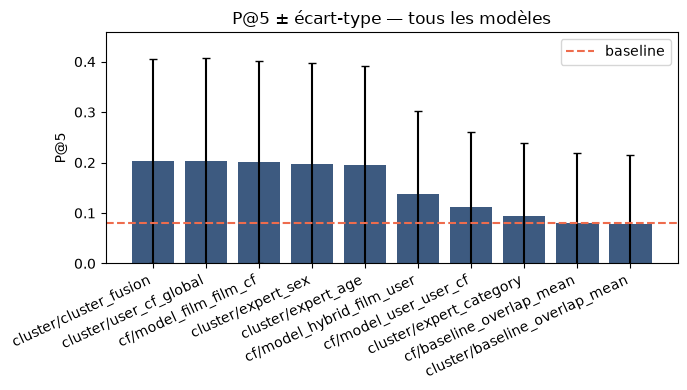

Écart-type élevé = P@5 très variable selon le profil / les seeds. Comparer surtout le P@5 moyen ; l'écart-type qualifie la stabilité.


In [2]:
methods = flatten_methods(bundles)
var_df = variance_table(methods)
display(var_df.round(4))

baseline_name = next(
    (m for m in var_df["method"] if m.endswith("/baseline_overlap_mean")),
    None,
)

plot_p5_variance(var_df, baseline_method=baseline_name)
plt.show()

print(
    "Écart-type élevé = P@5 très variable selon le profil / les seeds. "
    "Comparer surtout le P@5 moyen ; l'écart-type qualifie la stabilité."
)


### 3.2 Biais de popularité

Sur les **top-5** exportés : part des films dans le top-20 / top-100 du catalogue train (par volume de notes).


,method,source,rang pop. médian,top 20,top 21–100,hors top 100
0,cf/baseline_overlap_mean,cf,70.0,0.050,0.622,0.329
1,cf/model_user_user_cf,cf,18.0,0.573,0.340,0.086
2,cf/model_film_film_cf,cf,16.0,0.643,0.287,0.070
3,cf/model_hybrid_film_user,cf,14.0,0.631,0.293,0.077
4,cluster/baseline_overlap_mean,cluster,70.0,0.023,0.626,0.351
5,cluster/expert_sex,cluster,11.0,0.858,0.131,0.011
6,cluster/expert_age,cluster,11.0,0.842,0.128,0.030
7,cluster/expert_category,cluster,121.0,0.129,0.288,0.584
8,cluster/cluster_fusion,cluster,11.0,0.864,0.121,0.015
9,cluster/user_cf_global,cluster,11.0,0.893,0.100,0.007


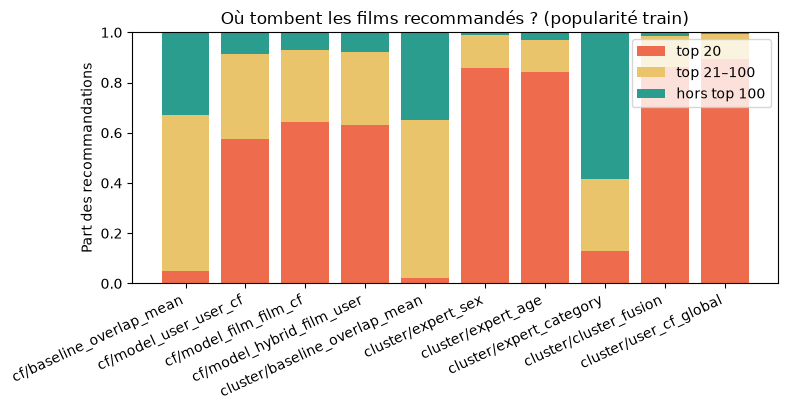

Plus la barre orange (top 20) est haute, plus le modèle recycle les films déjà très notés. Utile pour nuancer un bon P@5 : personnalisation vs popularité.


In [3]:
film_n = shared_film_n_ratings(bundles)
if film_n.empty:
    raise ValueError("film_n_ratings manquant dans les bundles")

bucket_df = popularity_table(methods, film_n)
display(bucket_df.round(3))

plot_popularity(bucket_df)
plt.show()

print(
    "Plus la barre orange (top 20) est haute, plus le modèle recycle les films "
    "déjà très notés. Utile pour nuancer un bon P@5 : personnalisation vs popularité."
)


### 3.3 Lecture diagnostics

- Un modèle avec **P@5 haut** et **forte part top-20** personnalise peu : il suit le catalogue populaire.
- Un modèle avec **P@5 correct** et plus de **hors top 100** explore davantage (souvent FilmCF / contenu).
- La **variance** indique si le score tient sur tous les profils ou seulement sur une partie des cas.


## 4. Interprétation globale

1. **La baseline est utile** : elle bat clairement le hasard et ancre le problème contenu (genres + qualité moyenne).
2. **Le CF User–User est le vrai levier** sur ce dataset et ce protocole cold-start (voisins = fans des seeds × démo). L'hybride n'ajoute presque rien quand `HYBRID_ALPHA` est très bas : FilmCF reste le parent pauvre.
3. **Goût vs popularité** : le CF personnalise (listes différentes par profil) mais recycle surtout le **top popularité**. Ce n'est pas un oracle niches.
4. **Le découpage cluster (sexe/âge/cat)** valide la critique du plan : experts en parallèle + fusion soft > cascade dure ; pourtant un UserCF global large reste devant. Sexe aide plus qu'âge/catégories seules.
5. **Plafond** : genres binaires pauvres, matrice sparse, label « aimé » relatif à la moyenne user. Empiler des seeds ou retuner `TRAIN_FRAC` ne débloque pas ; enrichir le contenu ou changer de modèle CF (ALS/SVD) serait le prochain levier.


## 5. Réponse produit

Pour un utilisateur qui saisit **âge, sexe, 1–3 films aimés**, le système le plus performant dans ce projet est aujourd'hui le **User–User CF** (ou l'hybride quasi équivalent).  
La baseline reste la référence pédagogique ; le cluster d'experts illustre une piste d'assemblage, sans battre le CF global sur MovieLens 100k.


## 6. Limites & suite

- Split aléatoire (pas temporel) ; horizon a posteriori charter.
- Pas d'`occupation`, pas de popularité comme feature modèle.
- Suite possible : figer `TRAIN_FRAC=0.7` partout, aligner Optuna → notebooks, tester ALS/SVD, métadonnées films (titre TF-IDF / année).
